In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error,
    explained_variance_score,
    max_error
)


In [2]:
df = pd.read_csv("../dataset/Fish.csv")
print("First 5 Rows")
print(df.head())
print("\nDataset Shape:", df.shape)


First 5 Rows
  Species  Weight  Length1  Length2  Length3   Height   Width
0   Bream   242.0     23.2     25.4     30.0  11.5200  4.0200
1   Bream   290.0     24.0     26.3     31.2  12.4800  4.3056
2   Bream   340.0     23.9     26.5     31.1  12.3778  4.6961
3   Bream   363.0     26.3     29.0     33.5  12.7300  4.4555
4   Bream   430.0     26.5     29.0     34.0  12.4440  5.1340

Dataset Shape: (159, 7)


In [3]:
# Convert Categorical Column into Numeric
df = pd.get_dummies(df, columns=['Species'], drop_first=True)


In [4]:
X = df.drop("Weight", axis=1)
y = df["Weight"]


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


In [6]:
# Polynomial Feature Transformation
poly = PolynomialFeatures(degree=2)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)


In [7]:
model = LinearRegression()

model.fit(X_train_poly, y_train)

# Prediction
y_pred = model.predict(X_test_poly)


In [8]:
# =====================================================
# Evaluation Metrics
# =====================================================

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred)
evs = explained_variance_score(y_test, y_pred)
maxerr = max_error(y_test, y_pred)

# Adjusted R²
n = X_test_poly.shape[0]
p = X_test_poly.shape[1] - 1

adj_r2 = 1 - ((1-r2)*(n-1)/(n-p-1))

print("\n========== Evaluation Metrics ==========")

print("MAE :", mae)
print("MSE :", mse)
print("RMSE :", rmse)
print("R2 Score :", r2)
print("Adjusted R2 :", adj_r2)
print("MAPE :", mape)
print("Explained Variance :", evs)
print("Maximum Error :", maxerr)



========== Evaluation Metrics ==========
MAE : 48.409823644000944
MSE : 5620.712917622992
RMSE : 74.97141400309182
R2 Score : 0.9604841036351225
Adjusted R2 : 1.026630277985026
MAPE : 0.2455305549696859
Explained Variance : 0.9618750799875218
Maximum Error : 266.1900881269826


In [9]:
# =====================================================
# Predict New Fish Weight
# =====================================================

sample = pd.DataFrame({
    "Length1":[25],
    "Length2":[27],
    "Length3":[30],
    "Height":[11],
    "Width":[4.5],
    "Species_Parkki":[0],
    "Species_Perch":[1],
    "Species_Pike":[0],
    "Species_Roach":[0],
    "Species_Smelt":[0],
    "Species_Whitefish":[0]
})

sample_poly = poly.transform(sample)

prediction = model.predict(sample_poly)

print("\nPredicted Weight =", prediction[0])



Predicted Weight = 513.371080796976


D:\JupyterLab\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


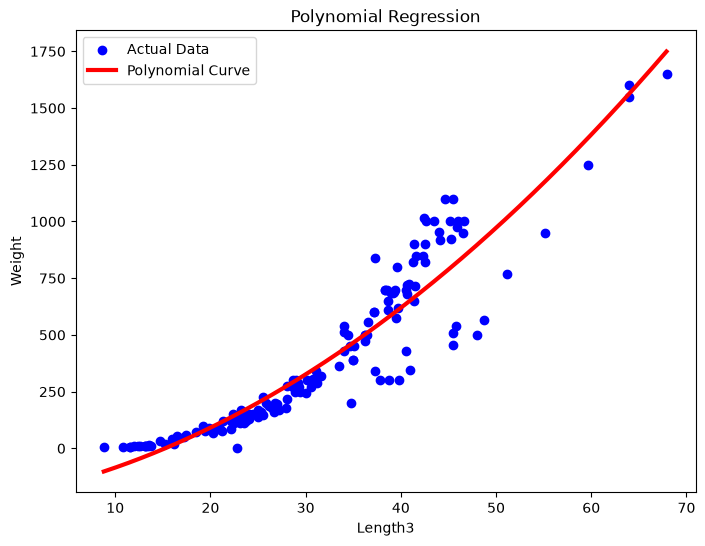

In [10]:
X = df[['Length3']]
y = df['Weight']
poly = PolynomialFeatures(degree=2)

X_poly = poly.fit_transform(X)

model = LinearRegression()
model.fit(X_poly, y)

X_grid = np.arange(
    X.min().values[0],
    X.max().values[0],
    0.1
).reshape(-1,1)

plt.figure(figsize=(8,6))

plt.scatter(X, y, color="blue", label="Actual Data")

plt.plot(
    X_grid,
    model.predict(poly.transform(X_grid)),
    color="red",
    linewidth=3,
    label="Polynomial Curve"
)

plt.xlabel("Length3")
plt.ylabel("Weight")
plt.title("Polynomial Regression")
plt.legend()
plt.show()
